# ACDC – Amazing Creative Desk Coworking
## Deliverable 1: Exploratory Data Analysis
**Data Mining · NOVA IMS · Fall 2026/27 · Group 31**

---

## Table of Contents

1. [Exploratory Data Analysis (EDA)](#1-exploratory-data-analysis-eda)  
2. [Data Cleaning and Preprocessing](#2-data-cleaning-and-preprocessing)  


---
## Students:
- Batoul Abdullah (20250536)  
- ??????  
- ?????

# 1.Exploratory Data Analysis (EDA)

In [1]:
#importing needed libraries 

In [2]:
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil
from scipy.stats import skewnorm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler


In [3]:
#importing the two datasets :

In [66]:
acdc = pd.read_csv(r"C:\Users\batoul.abdullah\Downloads\acdc_dataset.csv" , sep=";")

In [67]:
#checking the characteristics of the data :

In [69]:
acdc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  object 
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  object 
 3   industry                     15465 non-null  object 
 4   country                      15035 non-null  object 
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  object 
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  object 
 10  membership_end               15465 non-null  object 
 11  last_badge_swipe             15465 non-null  object 
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits    

In [68]:
acdc.shape

(15465, 31)

In [70]:
#checking the datatypes :

In [71]:
acdc.dtypes

member_id                       object
age                            float64
gender                          object
industry                        object
country                         object
is_team_account                   bool
n_colleagues_on_account          int64
plan_tier                       object
plan_days_per_week               int64
membership_start                object
membership_end                  object
last_badge_swipe                object
days_since_last_visit            int64
total_visits                     int64
avg_weekly_visits              float64
entitled_visits_last_period    float64
actual_visits_last_period        int64
meeting_room_hours             float64
event_space_hours              float64
guest_passes_issued            float64
uses_meeting_rooms                bool
uses_event_space                  bool
uses_guest_passes                 bool
uses_print                       int64
uses_mail_handling                bool
uses_phone_booths        

In [46]:
acdc.head()

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74


In [47]:
#checking the duplicates 

In [62]:
n_full_dup = acdc.duplicated().sum()
n_id_dup = acdc["member_id"].duplicated().sum()
print(f"Fully duplicated rows: {n_full_dup}")
print(f"Duplicated member_id: {n_id_dup}")

Fully duplicated rows: 15
Duplicated member_id: 15


In [49]:
#checking the missing values :

In [51]:
acdc.isna().sum()

member_id                         0
age                             558
gender                          530
industry                          0
country                         430
is_team_account                   0
n_colleagues_on_account           0
plan_tier                       105
plan_days_per_week                0
membership_start                  0
membership_end                    0
last_badge_swipe                  0
days_since_last_visit             0
total_visits                      0
avg_weekly_visits                 0
entitled_visits_last_period       0
actual_visits_last_period         0
meeting_room_hours             1298
event_space_hours                 0
guest_passes_issued            1271
uses_meeting_rooms                0
uses_event_space                  0
uses_guest_passes                 0
uses_print                        0
uses_mail_handling                0
uses_phone_booths                 0
uses_day_passes                   0
uses_storage                

In [74]:
missing = acdc.isna().sum().to_frame("n_missing")
missing["pct"] = 100 * missing["n_missing"] / len(acdc)
missing = missing[missing["n_missing"] > 0].sort_values("pct", ascending=False)
missing

,n_missing,pct
meeting_room_hours,1298,8.393146
guest_passes_issued,1271,8.218558
lifetime_value,1040,6.724863
age,558,3.608147
gender,530,3.427093
country,430,2.780472
plan_tier,105,0.678952


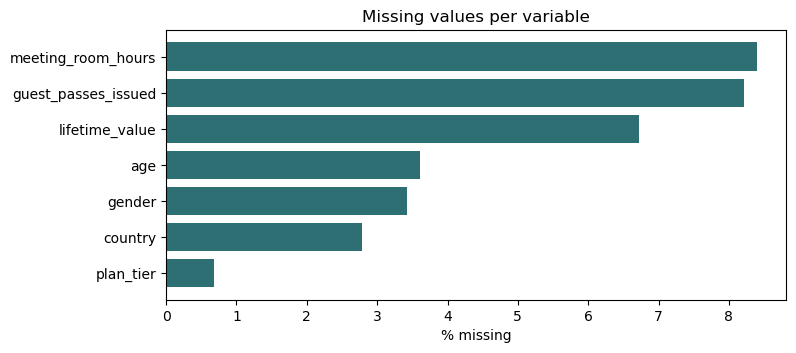

In [76]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(missing.index[::-1], missing["pct"][::-1], color="#2E6F73")
ax.set_xlabel("% missing"); ax.set_title("Missing values per variable")
plt.show()

In [ ]:
## descriptive statistics :

In [52]:
acdc.describe(include='all').transpose()

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
member_id,15465,15450,CW005845,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,14907.0,NaN,NaN,NaN,34.858724,10.394649,1.0,29.0,34.0,40.0,149.0
gender,14935,12,Female,7414,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry,15465,43,Information Technology,3322,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,15035,33,Portugal,9959,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_team_account,15465,2,False,11112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_colleagues_on_account,15465.0,NaN,NaN,NaN,0.537019,1.177668,-1.0,0.0,0.0,1.0,9.0
plan_tier,15360,19,flex,5182,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan_days_per_week,15465.0,NaN,NaN,NaN,3.387262,1.458818,0.0,2.0,3.0,5.0,9.0
membership_start,15465,1539,2021-01-01,560,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [53]:
acdc.describe(include=object).transpose()

,count,unique,top,freq
member_id,15465,15450,CW005845,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


In [56]:
acdc['gender'].unique()

array(['Female', 'Male', 'F', 'Other', nan, ' Female', 'M', 'male',
       ' Male', 'other', ' Other', 'female', 'O'], dtype=object)

In [58]:
acdc['industry'].unique()

array(['Information Technology', 'Education', 'Legal', 'Health',
       'Unknown', 'Other', 'Consulting', 'Design & Creative',
       'information technology', 'Finance', 'Marketing & PR', 'EDUCATION',
       'DESIGN & CREATIVE', 'Marketing and PR', 'Real Estate', 'other',
       'consulting', 'MARKETING & PR', 'Information technology',
       'design & creative', 'LEGAL', 'marketing & pr',
       'INFORMATION TECHNOLOGY', 'health', 'Marketing/PR', 'CONSULTING',
       'unknown', 'Design/Creative', 'RealEstate', 'IT', 'Tech',
       'Marketing & Pr', 'OTHER', 'legal', 'finance', 'real estate',
       'education', 'Design and Creative', 'UNKNOWN', 'FINANCE',
       'REAL ESTATE', 'HEALTH', 'Real-Estate'], dtype=object)

In [57]:
acdc['country'].unique()

array(['Portugal', 'DE', 'portugal', 'United Kingdom', 'Spain', 'Germany',
       'Netherlands', 'France', 'PT', 'Other (Europe)', 'Portucal', nan,
       'UK', 'Ireland', 'United kingdom', 'IE', 'portugal ',
       'Deutschland', 'ireland', 'germany', 'france', 'united kingdom',
       'other (europe)', 'U.K.', 'GB', 'ES', 'NL', 'España', 'Espana',
       'netherlands', 'spain', 'The Netherlands', 'FR', 'Holland'],
      dtype=object)

In [59]:
acdc['plan_tier'].unique()

array(['flex', 'HOT_DESK', 'hot_desk', 'dedicated_desk', 'full_time',
       'private_office', 'Hot Desk', 'dedicateddesk', nan, 'FULL_TIME',
       'hotdesk', 'Flex', 'FLEX', 'fulltime', 'privateoffice',
       'Full Time', 'DEDICATED_DESK', 'Dedicated Desk', 'Private Office',
       'PRIVATE_OFFICE'], dtype=object)

In [63]:
for col in ["gender", "country", "industry", "plan_tier"]:
    print(f"{col}: {acdc[col].nunique()} distinct raw values")
    print(acdc[col].value_counts(dropna=False).head(15).to_dict(), "\n")

gender: 12 distinct raw values
{'Female': 7414, 'Male': 6172, nan: 530, 'Other': 465, 'female': 169, 'F': 143, ' Female': 141, 'M': 138, 'male': 132, ' Male': 129, 'other': 15, ' Other': 9, 'O': 8} 

country: 33 distinct raw values
{'Portugal': 9959, 'United Kingdom': 1105, 'Germany': 852, 'Spain': 712, 'France': 506, 'Netherlands': 464, nan: 430, 'Other (Europe)': 429, 'Ireland': 232, 'portugal ': 155, 'Portucal': 142, 'PT': 130, 'portugal': 122, 'germany': 24, 'other (europe)': 22} 

industry: 43 distinct raw values
{'Information Technology': 3322, 'Consulting': 1896, 'Marketing & PR': 1835, 'Design & Creative': 1822, 'Finance': 1134, 'Other': 1100, 'Legal': 809, 'Education': 727, 'Unknown': 640, 'Health': 571, 'Real Estate': 528, 'CONSULTING': 86, 'consulting': 76, 'INFORMATION TECHNOLOGY': 54, 'IT': 53} 

plan_tier: 19 distinct raw values
{'flex': 5182, 'hot_desk': 4974, 'full_time': 2323, 'dedicated_desk': 1481, 'private_office': 630, 'Flex': 138, 'FLEX': 133, nan: 105, 'HOT_DESK'

All four categorical variables contain the same concept spelled several ways (case, leading spaces, abbreviations such as PT, UK, DE, typos such as Portucal, local names such as Deutschland or España). They must be harmonised before any grouping.

In [77]:
### 4.5 Impossible or suspicious values

In [79]:
checks = {
    "age < 18": (acdc["age"] < 18).sum(),
    "age > 80": (acdc["age"] > 80).sum(),
    "negative total_visits": (acdc["total_visits"] < 0).sum(),
    "negative meeting_room_hours": (acdc["meeting_room_hours"] < 0).sum(),
    "negative event_space_hours": (acdc["event_space_hours"] < 0).sum(),
    "negative guest_passes_issued": (acdc["guest_passes_issued"] < 0).sum(),
    "negative n_renewals": (acdc["n_renewals"] < 0).sum(),
    "negative n_colleagues": (acdc["n_colleagues_on_account"] < 0).sum(),
    "negative days_since_last_visit": (acdc["days_since_last_visit"] < 0).sum(),
    "plan_days_per_week not in {2,3,5,7}": (~acdc["plan_days_per_week"].isin([2, 3, 5, 7])).sum(),
    "membership_end < membership_start": ((tmp["membership_end"] < tmp["membership_start"]) & ~active).sum(),
    "last_badge_swipe < membership_start": (tmp["last_badge_swipe"] < tmp["membership_start"]).sum(),
    "last_badge_swipe after extraction date": (tmp["last_badge_swipe"] > REF_DATE).sum(),
}
pd.Series(checks, name="n_rows").to_frame()

NameError: name 'tmp' is not defined

# 2.Data Cleaning and Preprocessing

In [ ]:
#from the above Exploration and for better analysis we decided to do the following steps :

In [ ]:
#### Removing unneeded Columns :